# Low-rank Sinkhorn

We experiment with the low-rank {class}`~ott.solvers.linear.sinkhorn_lr.LRSinkhorn` solver, proposed by {cite}`scetbon:21` as an alternative to the {class}`~ott.solvers.linear.sinkhorn.Sinkhorn` algorithm.

The idea of that solver is to compute optimal transport couplings that are low-rank, by design. Rather than look for a $n\times m$ matrix $P_\varepsilon$ that has a factorization $D(u)\exp(-C/\varepsilon)D(v)$ (as computed by the Sinkhorn algorithm) when solving a problem with cost $C$, the set of feasible plans is restricted to those adopting a factorization of the form $P_r = Q D(1/g) R^T$, where $Q$ is $n\times r$, $R$ is $r \times m$ are two thin matrices, and $g$ is a $r$-dimensional probability vector.

In [1]:
import jax
import jax.numpy as jnp

import matplotlib.pyplot as plt

from ott.geometry import pointcloud
from ott.initializers.linear import initializers_lr
from ott.problems.linear import linear_problem
from ott.solvers.linear import sinkhorn, sinkhorn_lr
from ott.tools import plot

In [2]:
def create_points(rng, n, m, d):
    rngs = jax.random.split(rng, 4)
    x = jax.random.normal(rngs[0], (n, d)) + 1
    y = jax.random.uniform(rngs[1], (m, d))
    a = jax.random.uniform(rngs[2], (n,))
    b = jax.random.uniform(rngs[3], (m,))
    a = a / jnp.sum(a)
    b = b / jnp.sum(b)
    return x, y, a, b

Create a {class}`~ott.problems.linear.linear_problem.LinearProblem` comparing two {class}`point clouds <ott.geometry.pointcloud.PointCloud>`.

In [3]:
rng = jax.random.key(0)
n, m, d = 19, 35, 2
x, y, a, b = create_points(rng, n=n, m=m, d=d)

geom = pointcloud.PointCloud(x, y, epsilon=0.1)
ot_prob = linear_problem.LinearProblem(geom, a, b)

## Solve linear OT problem with Sinkhorn

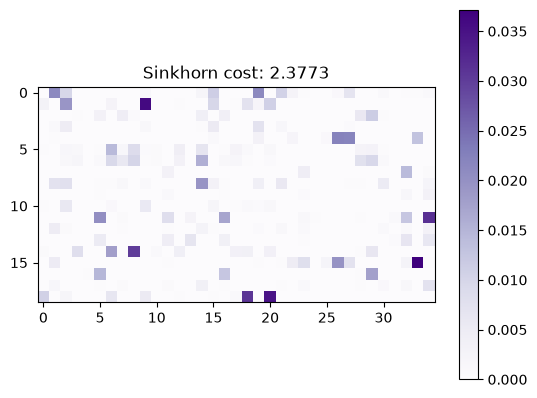

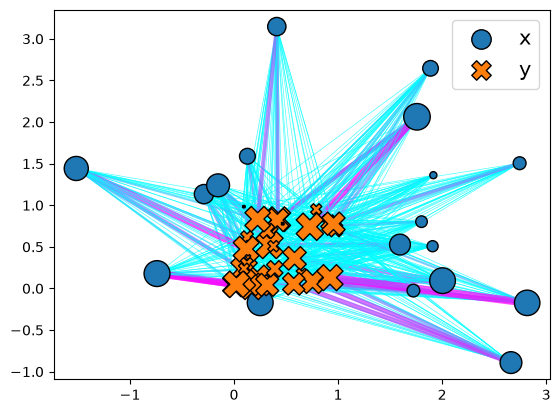

In [4]:
solver = sinkhorn.Sinkhorn()
ot_sink = solver(ot_prob)

plt.imshow(ot_sink.matrix, cmap="Purples")
plt.title(f"Sinkhorn cost: {ot_sink.primal_cost:.4f}")
plt.colorbar()
plt.show()
plott = plot.Plot()
_ = plott(ot_sink)

## Solve linear OT problem with low-rank Sinkhorn

Solve the problem using the {class}`~ott.solvers.linear.sinkhorn_lr.LRSinkhorn` solver, with a rank parameterized to be equal to the half of $r=\min(n,m)/2$

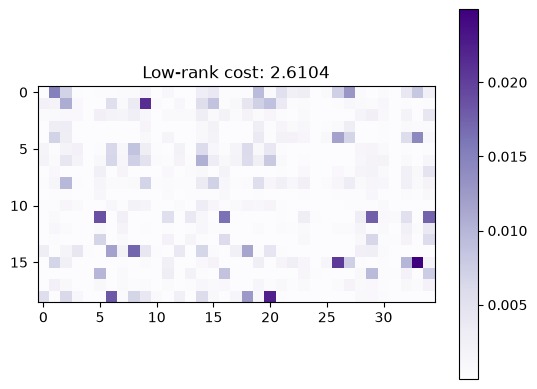

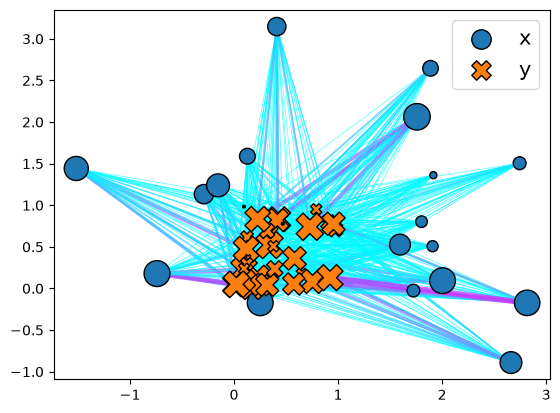

In [5]:
solver = sinkhorn_lr.LRSinkhorn(rank=int(min(n, m) / 2))
ot_lr = solver(ot_prob)

plt.imshow(ot_lr.matrix, cmap="Purples")
plt.colorbar()
plt.title(f"Low-rank cost: {ot_lr.primal_cost:.4f}")
plt.show()
plott = plot.Plot()
_ = plott(ot_lr)

## Play with larger scales

One of the interesting features of the low-rank approach lies in its ability to scale, since its iterations are of complexity $O( (n+m) r)$ rather than $O(nm)$. We consider this by sampling two points clouds of size $n=m=100\ 000$ in $d=7$.

In [6]:
n, m, d = 10**5, 10**5 + 1, 7
x, y, a, b = create_points(rng, n=n, m=m, d=d)

We compute plans that satisfy a rank constraint $r$, for various values of $r$. We use a smaller `threshold` than the default: otherwise, the solver stops after a few dozen iterations, when the change between successive iterates is small, before it improves on its initialization.

In [7]:
geom = pointcloud.PointCloud(x, y, epsilon=0.1)
ot_prob = linear_problem.LinearProblem(geom, a, b)
costs = []
ranks = [15, 20, 35, 50, 100]
for rank in ranks:
    initializer = initializers_lr.KMeansInitializer(rank)
    solver = jax.jit(
        sinkhorn_lr.LRSinkhorn(
            rank=rank,
            initializer=initializer,
            threshold=1e-6,
            max_iterations=3_000,
        )
    )
    ot_lr = solver(ot_prob)
    costs.append(ot_lr.reg_ot_cost)

As expected, the optimal cost decreases with rank, as shown in the plot below. Recall that, because of the non-convexity of the original problem, there may be small bumps along the way.

For these two fairly concentrated distributions, it seems possible to produce plans that have relatively small rank yet low cost.

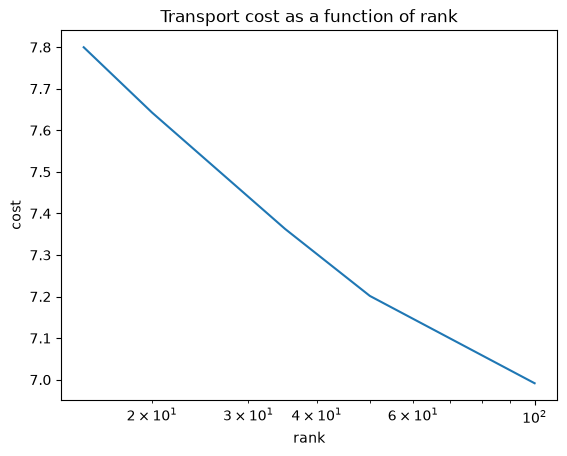

In [8]:
plt.plot(ranks, costs)
plt.xscale("log")
plt.xlabel("rank")
plt.ylabel("cost")
plt.title("Transport cost as a function of rank")
plt.show()